In [ ]:
!pip -q install "pandas==2.2.3" transformers accelerate matplotlib gradio

pandas — manages student records.
transformers — loads pretrained AI models
accelerate — helps run AI models efficiently.
matplotlib — creates performance charts.
gradio — builds the interactive app interface.
==2.2.3 — keeps Pandas at the version required by Colab.
-q — reduces installation output.

In [ ]:
import pandas as pd

data = {
    "Student": ["Asha", "Ravi", "Neha", "Arjun", "Priya",
                "Kiran", "Meera", "Rahul", "Sneha", "Vikram"],
    "Maths": [85, 62, 91, 48, 78, 55, 88, 70, 95, 66],
    "Python": [90, 58, 94, 52, 82, 60, 86, 75, 92, 69],
    "DBMS": [78, 65, 89, 45, 74, 57, 91, 68, 96, 72],
    "Attendance": [92, 68, 96, 61, 85, 72, 89, 78, 98, 74],
    "Assignment": [88, 60, 95, 50, 80, 58, 90, 73, 94, 67]
}

df = pd.DataFrame(data)

df

,Student,Maths,Python,DBMS,Attendance,Assignment
0,Asha,85,90,78,92,88
1,Ravi,62,58,65,68,60
2,Neha,91,94,89,96,95
3,Arjun,48,52,45,61,50
4,Priya,78,82,74,85,80
5,Kiran,55,60,57,72,58
6,Meera,88,86,91,89,90
7,Rahul,70,75,68,78,73
8,Sneha,95,92,96,98,94
9,Vikram,66,69,72,74,67


data — stores student information.
pd.DataFrame() — converts the data into a table.
df — the variable holding our dataset.
df at the end — displays the table in Colab.

In [ ]:
print("Dataset Shape:", df.shape)
print("\nDataset Information:")
print(df.info())
print("\nStatistical Summary:")
print(df.describe())
print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (10, 6)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Student     10 non-null     object
 1   Maths       10 non-null     int64 
 2   Python      10 non-null     int64 
 3   DBMS        10 non-null     int64 
 4   Attendance  10 non-null     int64 
 5   Assignment  10 non-null     int64 
dtypes: int64(5), object(1)
memory usage: 612.0+ bytes
None

Statistical Summary:
           Maths     Python       DBMS  Attendance  Assignment
count  10.000000  10.000000  10.000000   10.000000   10.000000
mean   73.800000  75.800000  73.500000   81.300000   75.500000
std    16.067911  15.339129  15.855248   12.570247   16.277114
min    48.000000  52.000000  45.000000   61.000000   50.000000
25%    63.000000  62.250000  65.750000   72.500000   61.750000
50%    74.000000  78.500000  73.000000   81.500000   76.500000
75%    87.2

df.shape — shows the number of rows and columns.
df.info() — shows column names, data types, and non-null counts.
df.describe() — calculates statistics such as mean, minimum, and maximum.
df.isnull().sum() — counts missing values in each column.
print() — displays the output.

In [ ]:
subjects = ["Maths", "Python", "DBMS"]

df["Average_Marks"] = df[subjects].mean(axis=1)

df["Performance"] = df["Average_Marks"].apply(
    lambda mark: "Excellent" if mark >= 85
    else "Good" if mark >= 70
    else "Needs Improvement"
)

df["Low_Attendance"] = df["Attendance"] < 75

df

,Student,Maths,Python,DBMS,Attendance,Assignment,Average_Marks,Performance,Low_Attendance
0,Asha,85,90,78,92,88,84.333333,Good,False
1,Ravi,62,58,65,68,60,61.666667,Needs Improvement,True
2,Neha,91,94,89,96,95,91.333333,Excellent,False
3,Arjun,48,52,45,61,50,48.333333,Needs Improvement,True
4,Priya,78,82,74,85,80,78.000000,Good,False
5,Kiran,55,60,57,72,58,57.333333,Needs Improvement,True
6,Meera,88,86,91,89,90,88.333333,Excellent,False
7,Rahul,70,75,68,78,73,71.000000,Good,False
8,Sneha,95,92,96,98,94,94.333333,Excellent,False
9,Vikram,66,69,72,74,67,69.000000,Needs Improvement,True


- subjects — lists the subjects to analyze.
- mean(axis=1) — calculates each student's average across the subject columns.
- apply() — applies a function to each value.
- lambda — creates a small, anonymous function.
- >= 85 — checks whether the average is at least 85.
- < 75 — flags attendance below 75%.
- df["Column"] — creates or accesses a DataFrame column.

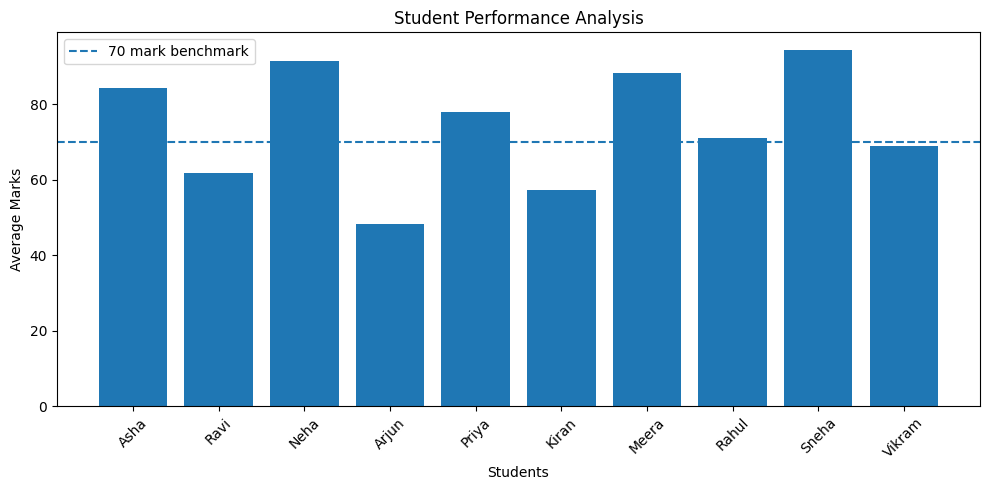

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.bar(df["Student"], df["Average_Marks"])
plt.axhline(y=70, linestyle="--", label="70 mark benchmark")
plt.title("Student Performance Analysis")
plt.xlabel("Students")
plt.ylabel("Average Marks")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
def answer_question(question):
    q = question.lower()

    if "average marks" in q or "class average" in q:
        return f"Class average: {df['Average_Marks'].mean():.2f}"

    elif "top student" in q or "highest marks" in q:
        student = df.loc[df["Average_Marks"].idxmax()]
        return f"Top student: {student['Student']} ({student['Average_Marks']:.2f})"

    elif "low attendance" in q or "below 75" in q:
        students = df.loc[df["Low_Attendance"], "Student"].tolist()
        return f"Students with attendance below 75%: {students}"

    elif "needs improvement" in q:
        students = df.loc[
            df["Performance"] == "Needs Improvement", "Student"
        ].tolist()
        return f"Students who need improvement: {students}"

    else:
        return "I can't answer that question yet. Try asking about class average, top student, low attendance, or students needing improvement."

In [ ]:
print(answer_question("Who is the top student?"))
print(answer_question("Which students have low attendance?"))
print(answer_question("What is the class average?"))

Top student: Sneha (94.33)
Students with attendance below 75%: ['Ravi', 'Arjun', 'Kiran', 'Vikram']
Class average: 74.37


In [2]:
import gradio as gr

# Define the function in the same cell to prevent NameError
def answer_question(question):
    q = question.lower()

    if "average marks" in q or "class average" in q:
        return f"Class average: {df['Average_Marks'].mean():.2f}"

    elif "top student" in q or "highest marks" in q:
        student = df.loc[df["Average_Marks"].idxmax()]
        return f"Top student: {student['Student']} ({student['Average_Marks']:.2f})"

    elif "low attendance" in q or "below 75" in q:
        students = df.loc[df["Low_Attendance"], "Student"].tolist()
        return f"Students with attendance below 75%: {students}"

    elif "needs improvement" in q:
        students = df.loc[
            df["Performance"] == "Needs Improvement", "Student"
        ].tolist()
        return f"Students who need improvement: {students}"

    else:
        return "I can't answer that question yet. Try asking about class average, top student, low attendance, or students needing improvement."

# Build the Gradio Interface
with gr.Blocks() as demo:
    gr.Markdown("# 🎓 AI Student Performance Analyst")
    gr.Markdown("Ask questions about student marks and attendance.")

    question = gr.Textbox(
        label="Ask your question",
        placeholder="e.g. Who is the top student?",
    )

    button = gr.Button("Analyze", variant="primary")
    answer = gr.Textbox(label="Analysis Result", lines=3)

    button.click(
        fn=answer_question,
        inputs=question,
        outputs=answer
    )

    gr.Examples(
        examples=[
            ["Who is the top student?"],
            ["What is the class average?"],
            ["Which students have low attendance?"],
            ["Which students need improvement?"]
        ],
        inputs=question
    )

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://a15bbb3d6f7d813756.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


gr.Blocks() — creates the app layout.
gr.Markdown() — displays headings and descriptions.
gr.Textbox() — accepts questions and displays answers
gr.Button() — creates the Analyze button.
button.click() — connects the button to your Python function.
gr.Examples() — provides sample questions.
demo.launch(share=True) — launches the app and creates a shareable link.

In [3]:
def analyze_csv(file):
    if file is None:
        return "Please upload a CSV file."

    uploaded_df = pd.read_csv(file)
    numeric_df = uploaded_df.select_dtypes(include="number")

    if numeric_df.empty:
        return "No numeric columns found in the uploaded file."

    return numeric_df.describe().round(2).to_string()

with gr.Blocks(theme=gr.themes.Soft()) as analysis_app:
    gr.Markdown("# 📊 Student Dataset Analyzer")
    file = gr.File(label="Upload CSV", file_types=[".csv"])
    result = gr.Textbox(label="Statistical Summary", lines=12)
    button = gr.Button("Analyze Dataset", variant="primary")

    button.click(analyze_csv, inputs=file, outputs=result)

analysis_app.launch(share=True)

/tmp/ipykernel_2649/2992864370.py:13: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as analysis_app:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ff30b2f5e2920564b9.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
df.to_csv("student_performance.csv", index=False)

from google.colab import files
files.download("student_performance.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:
def plot_student_marks(file):
    if file is None:
        return None

    uploaded_df = pd.read_csv(
        file.name if hasattr(file, "name") else file
    )

    required = ["Student", "Maths", "Python", "DBMS"]
    if not all(col in uploaded_df.columns for col in required):
        raise gr.Error("CSV must contain Student, Maths, Python and DBMS columns.")

    uploaded_df["Average"] = uploaded_df[["Maths", "Python", "DBMS"]].mean(axis=1)

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.bar(uploaded_df["Student"], uploaded_df["Average"])
    ax.set_title("Average Marks by Student")
    ax.set_xlabel("Student")
    ax.set_ylabel("Average Marks")
    ax.tick_params(axis="x", rotation=45)
    fig.tight_layout()
    return fig

with gr.Blocks(theme=gr.themes.Soft()) as chart_app:
    gr.Markdown("# 📈 Student Performance Visualization")
    csv_file = gr.File(label="Upload student CSV", file_types=[".csv"])
    chart_button = gr.Button("Generate Chart")
    chart_output = gr.Plot(label="Average Marks")

    chart_button.click(
        fn=plot_student_marks,
        inputs=csv_file,
        outputs=chart_output
    )

chart_app.launch(share=True)

/tmp/ipykernel_2649/3986270034.py:24: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as chart_app:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://44b33e112a94aba479.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


required — the column names needed in the CSV.
all() — checks that every required column exists.
plt.subplots() — creates a figure and chart area.
ax.bar() — draws the bar chart.
gr.Plot() — displays the chart in Gradio.
gr.Error() — shows a helpful error if the CSV format is incorrect.

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import gradio as gr

def analyze_file(file, question):
    if file is None:
        raise gr.Error("Please upload a CSV file first.")

    path = file.name if hasattr(file, "name") else file
    data = pd.read_csv(path)

    if data.empty:
        raise gr.Error("The CSV file is empty.")

    numeric = data.select_dtypes(include="number")
    preview = data.head(10)

    if numeric.empty:
        summary = "No numeric columns found."
        chart = None
    else:
        summary = numeric.describe().round(2).to_string()

        chart, ax = plt.subplots(figsize=(8, 4))
        numeric.mean().plot(kind="bar", ax=ax)
        ax.set_title("Average Value by Numeric Column")
        ax.set_ylabel("Average")
        chart.tight_layout()

    q = (question or "").lower()
    answer = "Try asking about the average, maximum, minimum, or number of rows."

    if "row" in q or "student" in q and "top" not in q:
        answer = f"The dataset contains {len(data)} rows."
    elif "column" in q:
        answer = f"Columns: {', '.join(data.columns)}"
    elif not numeric.empty and "average" in q:
        answer = numeric.mean().round(2).to_string()
    elif not numeric.empty and ("maximum" in q or "highest" in q):
        answer = numeric.max().to_string()
    elif not numeric.empty and ("minimum" in q or "lowest" in q):
        answer = numeric.min().to_string()

    return preview, summary, chart, answer

with gr.Blocks(theme=gr.themes.Soft()) as demo:
    gr.Markdown("# 🎓 AI Student Performance Analyst")
    gr.Markdown("Upload a CSV to explore records, statistics, charts, and answers.")

    file = gr.File(label="📂 Upload CSV", file_types=[".csv"])
    question = gr.Textbox(
        label="Ask about your data",
        placeholder="e.g. What is the average mark?"
    )
    analyze = gr.Button("Analyze Dataset", variant="primary")

    preview = gr.Dataframe(label="Dataset Preview")
    summary = gr.Textbox(label="Statistical Summary", lines=10)
    chart = gr.Plot(label="Data Visualization")
    answer = gr.Textbox(label="Answer")

    analyze.click(
        fn=analyze_file,
        inputs=[file, question],
        outputs=[preview, summary, chart, answer]
    )

demo.launch(share=True)

/tmp/ipykernel_2649/3223342380.py:46: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://af7d92a935cc8c26e9.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


analyze_file() — processes the uploaded CSV.
pd.read_csv() — reads the file into a DataFrame.
describe() — calculates statistical summaries.
plot(kind="bar") — creates a bar chart.
gr.Blocks() — arranges the dashboard components.
analyze.click() — runs the analysis when the button is clicked.
share=True — creates a shareable Gradio link.

In [ ]:
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer, pipeline

model_name = "google/flan-t5-small"
model = AutoModelForSeq2SeqLM.from_pretrained(model_name)
tokenizer = AutoTokenizer.from_pretrained(model_name)

# By explicitly passing the "text-generation" task with our loaded seq2seq model,
# we avoid automatic task inference errors and remain compatible with transformers v5.
ai_model = pipeline(
    task="text-generation",
    model=model,
    tokenizer=tokenizer
)

print("Pretrained AI model loaded successfully!")

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.
[transformers] The model 'T5ForConditionalGeneration' is not supported for text-generation. Supported models are ['PeftModelForCausalLM', 'AfmoeForCausalLM', 'ApertusForCausalLM', 'ArceeForCausalLM', 'AriaTextForCausalLM', 'AXK1ForCausalLM', 'AXK2ForCausalLM', 'BailingHybridForCausalLM', 'BambaForCausalLM', 'BartForCausalLM', 'BeamForCausalLM', 'BertLMHeadModel', 'BertGenerationDecoder', 'BigBirdForCausalLM', 'BigBirdPegasusForCausalLM', 'BioGptForCausalLM', 'BitNetForCausalLM', 'BlenderbotForCausalLM', 'BlenderbotSmallForCausalLM', 'BloomForCausalLM', 'BltForCausalLM', 'CamembertForCausalLM', 'CodeGenForCausalLM', 'CohereForCausalLM', 'Cohere2ForCausalLM', 'Cohere2MoeForCausalLM', 'CohereCompassForC

Pretrained AI model loaded successfully!


In [ ]:
if 'ai_model' not in locals() and 'ai_model' not in globals():
    from transformers import AutoModelForSeq2SeqLM, AutoTokenizer, pipeline
    model_name = "google/flan-t5-small"
    model = AutoModelForSeq2SeqLM.from_pretrained(model_name)
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    ai_model = pipeline(
        "text-generation",
        model=model,
        tokenizer=tokenizer
    )

result = ai_model(
    "Answer briefly: Why is attendance important for students?",
    max_new_tokens=60
)

print(result[0]["generated_text"])

Answer briefly: Why is attendance important for students?


In [ ]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

model_name = "google/flan-t5-small"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

prompt = "Answer briefly: Why is attendance important for students?"
inputs = tokenizer(prompt, return_tensors="pt")
outputs = model.generate(**inputs, max_new_tokens=60)

answer = tokenizer.decode(outputs[0], skip_special_tokens=True)
print(answer)

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


a student is a student


In [ ]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

model_name = "google/flan-t5-small"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

print("FLAN-T5 loaded successfully!")


Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


FLAN-T5 loaded successfully!


In [ ]:
prompt = "Answer briefly: Why is attendance important for students?"

inputs = tokenizer(prompt, return_tensors="pt")
outputs = model.generate(**inputs, max_new_tokens=60)

answer = tokenizer.decode(outputs[0], skip_special_tokens=True)
print(answer)

a student is a student


In [ ]:
prompt = """
Explain in one sentence how regular attendance helps students
understand lessons and improve their academic performance.
"""

inputs = tokenizer(prompt, return_tensors="pt")
outputs = model.generate(
    **inputs,
    max_new_tokens=80,
    num_beams=4,
    no_repeat_ngram_size=3,
    early_stopping=True
)

answer = tokenizer.decode(outputs[0], skip_special_tokens=True)
print(answer)

Regular attendance helps students understand lessons and improve their academic performance.


In [ ]:
def interpret_question(question):
    prompt = f"""
    Classify the question into exactly one category:
    AVERAGE, MAXIMUM, MINIMUM, ROW_COUNT, COLUMNS, or OTHER.

    Question: {question}
    Category:
    """

    inputs = tokenizer(prompt, return_tensors="pt")
    outputs = model.generate(
        **inputs,
        max_new_tokens=10,
        num_beams=4
    )

    return tokenizer.decode(
        outputs[0], skip_special_tokens=True
    ).strip().upper()

print(interpret_question("What is the average mark?"))
print(interpret_question("How many students are there?"))

OTHER
OTHER


In [ ]:
def interpret_question(question):
    prompt = f"""
    Choose the best label for the question.
    Labels: AVERAGE, MAXIMUM, MINIMUM, ROW_COUNT, COLUMNS, OTHER.

    Examples:
    Question: What is the average mark?
    Label: AVERAGE

    Question: Who scored the highest?
    Label: MAXIMUM

    Question: What is the lowest score?
    Label: MINIMUM

    Question: How many students are there?
    Label: ROW_COUNT

    Question: What are the column names?
    Label: COLUMNS

    Question: {question}
    Label:
    """

    inputs = tokenizer(prompt, return_tensors="pt")
    outputs = model.generate(
        **inputs,
        max_new_tokens=12,
        num_beams=4
    )

    return tokenizer.decode(outputs[0], skip_special_tokens=True).strip().upper()

for q in [
    "What is the average mark?",
    "How many students are there?",
    "Who scored the highest?",
    "What are the column names?"
]:
    print(q, "->", interpret_question(q))

What is the average mark? -> OTHER
How many students are there? -> OTHER
Who scored the highest? -> OTHER
What are the column names? -> OTHER


In [ ]:
def interpret_question(question):
    q = question.lower().strip()

    if any(word in q for word in ["average", "mean"]):
        return "AVERAGE"

    elif any(word in q for word in ["highest", "maximum", "max", "top student"]):
        return "MAXIMUM"

    elif any(word in q for word in ["lowest", "minimum", "min"]):
        return "MINIMUM"

    elif any(word in q for word in ["how many", "number of", "count"]):
        return "ROW_COUNT"

    elif any(word in q for word in ["column", "field", "headers"]):
        return "COLUMNS"

    else:
        return "OTHER"

In [ ]:
questions = [
    "What is the average mark?",
    "How many students are there?",
    "Who scored the highest?",
    "What are the column names?"
]

for q in questions:
    print(q, "->", interpret_question(q))

In [ ]:
def answer_data_question(data, question):
    if data is None:
        return "Please upload a CSV file first."

    intent = interpret_question(question)
    numeric = data.select_dtypes(include="number")

    if intent == "AVERAGE":
        if numeric.empty:
            return "No numeric columns found."
        return "Average values:\n" + numeric.mean().round(2).to_string()

    elif intent == "MAXIMUM":
        if numeric.empty:
            return "No numeric columns found."
        return "Maximum values:\n" + numeric.max().to_string()

    elif intent == "MINIMUM":
        if numeric.empty:
            return "No numeric columns found."
        return "Minimum values:\n" + numeric.min().to_string()

    elif intent == "ROW_COUNT":
        return f"Number of rows: {len(data)}"

    elif intent == "COLUMNS":
        return "Columns: " + ", ".join(data.columns)

    else:
        return "Try asking about average, highest, lowest, row count, or column names."

In [ ]:

def analyze_file(file, question):
    if file is None:
        raise gr.Error("Please upload a CSV file first.")

    try:
        path = file.name if hasattr(file, "name") else file
        data = pd.read_csv(path)

        if data.empty:
            raise gr.Error("The CSV file is empty.")

        numeric = data.select_dtypes(include="number")
        preview = data.head(10)

        if numeric.empty:
            summary = "No numeric columns found."
            chart = None
        else:
            summary = numeric.describe().round(2).to_string()
            chart, ax = plt.subplots(figsize=(8, 4))
            numeric.mean().plot(kind="bar", ax=ax)
            ax.set_title("Average Value by Numeric Column")
            ax.set_ylabel("Average")
            chart.tight_layout()

        answer = answer_data_question(data, question)

        return preview, summary, chart, answer

    except gr.Error:
        raise
    except Exception as e:
        raise gr.Error(f"Could not analyze the CSV: {e}")


In [ ]:

def generate_ai_explanation(question, result):
    prompt = f"""
    You are a student performance data analyst.
    Explain this analysis result in simple English.
    Question: {question}
    Analysis result: {result}
    Give a short explanation in 2 sentences.
    """

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=512
    )

    outputs = model.generate(
        **inputs,
        max_new_tokens=80,
        num_beams=4
    )

    explanation = tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

    return explanation


In [ ]:
result = "The class average is 74.37 marks."

print(generate_ai_explanation(
    "What is the class average?",
    result
))

The class average is 74.37 marks. So, the average is 74.37 marks. So, the average is 74.37 marks. So, the average is 74.37 marks. So, the average is 74.37 marks. So, the average is 74.37 marks. So, the average is 74.37 marks. So, the average


In [ ]:

def analyze_file(file, question):
    if file is None:
        raise gr.Error("Please upload a CSV file first.")

    try:
        path = file.name if hasattr(file, "name") else file
        data = pd.read_csv(path)

        if data.empty:
            raise gr.Error("The CSV file is empty.")

        numeric = data.select_dtypes(include="number")
        preview = data.head(10)

        if numeric.empty:
            summary = "No numeric columns found."
            chart = None
        else:
            summary = numeric.describe().round(2).to_string()
            chart, ax = plt.subplots(figsize=(8, 4))
            numeric.mean().plot(kind="bar", ax=ax)
            ax.set_title("Average Value by Numeric Column")
            ax.set_ylabel("Average")
            chart.tight_layout()

        result = answer_data_question(data, question)

        if result.startswith("Try asking"):
            answer = result
        else:
            explanation = generate_ai_explanation(question, result)
            answer = f"Calculated result:\n{result}\n\nAI explanation:\n{explanation}"

        return preview, summary, chart, answer

    except gr.Error:
        raise
    except Exception as e:
        raise gr.Error(f"Could not analyze the CSV: {e}")


In [6]:

import pandas as pd
import matplotlib.pyplot as plt
import gradio as gr

# 1. Calculate dashboard KPI metrics
def calculate_kpis(data):
    subjects = [
        col for col in ["Maths", "Python", "DBMS"]
        if col in data.columns
    ]

    total_students = len(data)

    if total_students == 0:
        return {
            "total_students": 0,
            "class_average": 0,
            "top_student": "N/A",
            "low_attendance": 0
        }

    if subjects:
        averages = data[subjects].mean(axis=1)
        class_average = round(float(averages.mean()), 2)

        if "Student" in data.columns:
            top_student = str(data.loc[averages.idxmax(), "Student"])
        else:
            top_student = "N/A"
    else:
        averages = None
        class_average = 0
        top_student = "N/A"

    low_attendance = (
        int((data["Attendance"] < 75).sum())
        if "Attendance" in data.columns else 0
    )

    return {
        "total_students": total_students,
        "class_average": class_average,
        "top_student": top_student,
        "low_attendance": low_attendance
    }


# 2. Answer questions using the uploaded dataset
def answer_data_question(data, question):
    q = (question or "").lower().strip()
    numeric = data.select_dtypes(include="number")

    if any(word in q for word in ["average", "mean"]):
        if numeric.empty:
            return "No numeric columns found."
        return "Average values:\n" + numeric.mean().round(2).to_string()

    elif any(word in q for word in ["highest", "maximum", "max", "top student"]):
        if numeric.empty:
            return "No numeric columns found."
        if "Student" in data.columns and any(
            word in q for word in ["student", "scored", "highest", "top"]
        ):
            subjects = [
                c for c in ["Maths", "Python", "DBMS"] if c in data.columns
            ]
            if subjects:
                averages = data[subjects].mean(axis=1)
                idx = averages.idxmax()
                return (
                    f"Top student: {data.loc[idx, 'Student']} "
                    f"with an average of {averages.loc[idx]:.2f}"
                )
        return "Maximum values:\n" + numeric.max().to_string()

    elif any(word in q for word in ["lowest", "minimum", "min"]):
        if numeric.empty:
            return "No numeric columns found."
        return "Minimum values:\n" + numeric.min().to_string()

    elif any(word in q for word in ["how many", "number of", "count", "students"]):
        return f"Number of rows in the dataset: {len(data)}"

    elif any(word in q for word in ["column", "field", "headers"]):
        return "Columns: " + ", ".join(data.columns)

    elif "attendance" in q and any(word in q for word in ["low", "below", "less"]):
        if "Attendance" not in data.columns:
            return "The dataset has no Attendance column."
        count = int((data["Attendance"] < 75).sum())
        names = (
            data.loc[data["Attendance"] < 75, "Student"].tolist()
            if "Student" in data.columns else []
        )
        return f"Students with attendance below 75%: {count}. {names}"

    return (
        "Try asking about average marks, top student, highest or lowest "
        "values, student count, column names, or low attendance."
    )


# 3. Generate a short explanation using the loaded FLAN-T5 model
def generate_ai_explanation(question, result):
    try:
        prompt = (
            "Explain this data analysis result in simple English in one "
            "or two sentences.\n"
            f"Question: {question}\n"
            f"Result: {result}\n"
            "Explanation:"
        )

        inputs = tokenizer(
            prompt,
            return_tensors="pt",
            truncation=True,
            max_length=512
        )

        outputs = model.generate(
            **inputs,
            max_new_tokens=80,
            num_beams=4
        )

        explanation = tokenizer.decode(
            outputs[0],
            skip_special_tokens=True
        )

        return explanation or "The result was calculated successfully."
    except Exception as e:
        return f"AI explanation unavailable: {e}"


# 4. Analyze the uploaded CSV
def analyze_file(file, question):
    if file is None:
        raise gr.Error("Please upload a CSV file first.")

    try:
        path = file.name if hasattr(file, "name") else file
        data = pd.read_csv(path)

        if data.empty:
            raise gr.Error("The CSV file is empty.")

        kpis = calculate_kpis(data)
        preview = data.head(10)

        numeric = data.select_dtypes(include="number")

        if numeric.empty:
            summary = "No numeric columns found."
            chart = None
        else:
            summary = numeric.describe().round(2).to_string()
            chart, ax = plt.subplots(figsize=(8, 4))
            numeric.mean().plot(kind="bar", ax=ax)
            ax.set_title("Average Value by Numeric Column")
            ax.set_ylabel("Average")
            chart.tight_layout()

        result = answer_data_question(data, question)

        if result.startswith("Try asking"):
            answer = result
        else:
            explanation = generate_ai_explanation(question, result)
            answer = (
                f"CALCULATED RESULT\n{result}\n\n"
                f"AI EXPLANATION\n{explanation}"
            )

        return (
            preview,
            summary,
            chart,
            answer,
            str(kpis["total_students"]),
            str(kpis["class_average"]),
            kpis["top_student"],
            str(kpis["low_attendance"])
        )

    except gr.Error:
        raise
    except Exception as e:
        raise gr.Error(f"Could not analyze the CSV: {e}")


# 5. Build the complete dashboard interface
with gr.Blocks(theme=gr.themes.Soft()) as demo:
    gr.Markdown("# 🎓 AI Student Performance Analyst")
    gr.Markdown(
        "### Smart Academic Insights Dashboard\n"
        "Upload a CSV to explore student performance."
    )

    file = gr.File(
        label="📂 Upload Student CSV",
        file_types=[".csv"]
    )

    with gr.Row():
        total_card = gr.Textbox(
            label="👥 Total Students",
            interactive=False
        )
        average_card = gr.Textbox(
            label="📊 Class Average",
            interactive=False
        )

    with gr.Row():
        top_card = gr.Textbox(
            label="🏆 Top Performer",
            interactive=False
        )
        attendance_card = gr.Textbox(
            label="⚠️ Low Attendance (<75%)",
            interactive=False
        )

    question = gr.Textbox(
        label="💬 Ask about your data",
        placeholder="e.g. Who is the top student?"
    )

    analyze = gr.Button("Analyze Dataset", variant="primary")

    preview = gr.Dataframe(label="📋 Dataset Preview")
    summary = gr.Textbox(label="📈 Statistical Summary", lines=8)
    chart = gr.Plot(label="📊 Data Visualization")
    answer = gr.Textbox(label="🤖 Analysis and AI Explanation", lines=7)

    analyze.click(
        fn=analyze_file,
        inputs=[file, question],
        outputs=[
            preview,
            summary,
            chart,
            answer,
            total_card,
            average_card,
            top_card,
            attendance_card
        ]
    )

    gr.Examples(
        examples=[
            ["Who is the top student?"],
            ["What is the average mark?"],
            ["Which students have low attendance?"],
            ["How many students are there?"],
            ["What are the column names?"]
        ],
        inputs=question
    )

demo.launch(share=True)


/tmp/ipykernel_2649/2897170323.py:194: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://95aa6e8673458ce1fa.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


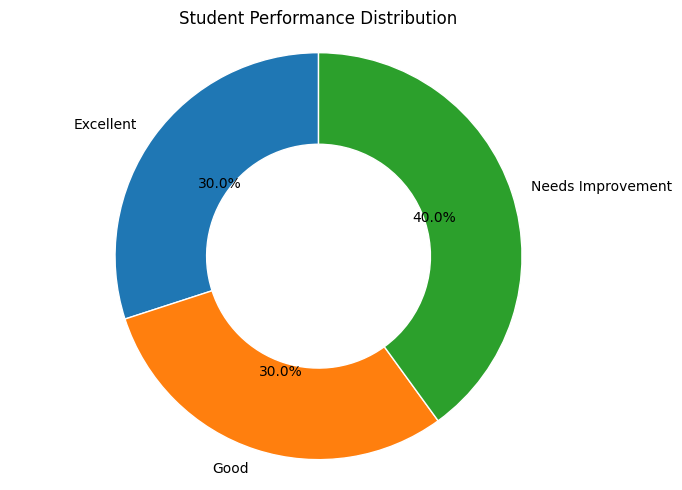

In [ ]:

import matplotlib.pyplot as plt

def plot_performance_pie(data):
    subjects = ["Maths", "Python", "DBMS"]

    if not all(col in data.columns for col in subjects):
        raise ValueError(
            "CSV must contain Maths, Python and DBMS columns."
        )

    averages = data[subjects].mean(axis=1)

    categories = {
        "Excellent": int((averages >= 85).sum()),
        "Good": int(((averages >= 70) & (averages < 85)).sum()),
        "Needs Improvement": int((averages < 70).sum())
    }

    labels = [name for name, count in categories.items() if count > 0]
    values = [count for count in categories.values() if count > 0]

    fig, ax = plt.subplots(figsize=(7, 5))

    ax.pie(
        values,
        labels=labels,
        autopct="%1.1f%%",
        startangle=90,
        wedgeprops={"width": 0.45, "edgecolor": "white"}
    )

    ax.set_title("Student Performance Distribution")
    ax.axis("equal")
    fig.tight_layout()

    return fig

plot_performance_pie(df)
plt.show()


In [7]:

import pandas as pd
import matplotlib.pyplot as plt
import gradio as gr

# ---------- KPI CARDS ----------
def calculate_kpis(data):
    subjects = [c for c in ["Maths", "Python", "DBMS"] if c in data.columns]

    if data.empty:
        return 0, 0, "N/A", 0

    averages = data[subjects].mean(axis=1) if subjects else None
    class_avg = round(float(averages.mean()), 2) if subjects else 0

    top_student = (
        str(data.loc[averages.idxmax(), "Student"])
        if subjects and "Student" in data.columns else "N/A"
    )

    low_attendance = (
        int((data["Attendance"] < 75).sum())
        if "Attendance" in data.columns else 0
    )

    return len(data), class_avg, top_student, low_attendance


# ---------- QUESTION ANSWERING ----------
def answer_question(data, question):
    q = (question or "").lower()
    numeric = data.select_dtypes(include="number")
    subjects = [c for c in ["Maths", "Python", "DBMS"] if c in data.columns]

    if "column" in q or "header" in q:
        return "Columns: " + ", ".join(data.columns)

    if "attendance" in q and any(w in q for w in ["low", "below", "less"]):
        if "Attendance" not in data.columns:
            return "No Attendance column found."
        low = data[data["Attendance"] < 75]
        names = low["Student"].tolist() if "Student" in data.columns else []
        return f"Students below 75% attendance: {len(low)}. {names}"

    if any(w in q for w in ["how many", "number of students", "student count"]):
        return f"Total rows in dataset: {len(data)}"

    if any(w in q for w in ["top student", "highest marks", "scored highest"]):
        if subjects and "Student" in data.columns:
            avg = data[subjects].mean(axis=1)
            i = avg.idxmax()
            return f"Top student: {data.loc[i, 'Student']}, average {avg.loc[i]:.2f}"
        return numeric.max().to_string() if not numeric.empty else "No numeric data."

    if "average" in q or "mean" in q:
        if subjects:
            return f"Average marks: {data[subjects].mean().round(2).to_dict()}"
        return numeric.mean().round(2).to_string() if not numeric.empty else "No numeric data."

    if any(w in q for w in ["lowest", "minimum"]):
        return numeric.min().to_string() if not numeric.empty else "No numeric data."

    return "Try asking about average marks, top student, lowest values, attendance, student count, or column names."


# ---------- AI EXPLANATION ----------
def explain_result(question, result):
    try:
        prompt = (
            "Explain this data result in simple English in one or two sentences.\n"
            f"Question: {question}\nResult: {result}\nExplanation:"
        )
        inputs = tokenizer(prompt, return_tensors="pt", truncation=True, max_length=512)
        outputs = model.generate(**inputs, max_new_tokens=70, num_beams=4)
        return tokenizer.decode(outputs[0], skip_special_tokens=True)
    except Exception:
        return "The result above was calculated from the uploaded dataset."


# ---------- CHARTS ----------
def make_charts(data):
    subjects = [c for c in ["Maths", "Python", "DBMS"] if c in data.columns]

    # Doughnut chart: performance categories
    pie_fig, ax = plt.subplots(figsize=(5, 4))

    if subjects:
        avg = data[subjects].mean(axis=1)
        counts = [
            int((avg >= 85).sum()),
            int(((avg >= 70) & (avg < 85)).sum()),
            int((avg < 70).sum())
        ]
        labels = ["Excellent (85+)", "Good (70–84)", "Needs Improvement (<70)"]
        present = [(l, c) for l, c in zip(labels, counts) if c > 0]

        if present:
            labels, counts = zip(*present)
            ax.pie(
                counts,
                labels=labels,
                autopct="%1.1f%%",
                startangle=90,
                wedgeprops={"width": 0.45}
            )
            ax.set_title("Performance Distribution")
        else:
            ax.text(0.5, 0.5, "No performance data", ha="center")
    else:
        ax.text(0.5, 0.5, "Need Maths, Python and DBMS columns", ha="center")

    pie_fig.tight_layout()

    # Subject comparison bar chart
    bar_fig, bx = plt.subplots(figsize=(6, 4))

    if subjects:
        data[subjects].mean().plot(kind="bar", ax=bx)
        bx.set_title("Average Marks by Subject")
        bx.set_ylabel("Average Marks")
        bx.set_ylim(bottom=0)
    else:
        bx.text(0.5, 0.5, "No supported subject columns", ha="center")

    bar_fig.tight_layout()
    return pie_fig, bar_fig


# ---------- MAIN ANALYSIS ----------
def analyze_dashboard(file, question):
    if file is None:
        raise gr.Error("Please upload a CSV file.")

    try:
        path = file.name if hasattr(file, "name") else file
        data = pd.read_csv(path)

        if data.empty:
            raise gr.Error("The CSV file is empty.")

        total, class_avg, top, low = calculate_kpis(data)
        numeric = data.select_dtypes(include="number")

        summary = (
            numeric.describe().round(2).to_string()
            if not numeric.empty else "No numeric columns found."
        )

        pie_fig, bar_fig = make_charts(data)
        result = answer_question(data, question)

        if result.startswith("Try asking"):
            final_answer = result
        else:
            explanation = explain_result(question, result)
            final_answer = (
                f"CALCULATED RESULT\n{result}\n\n"
                f"AI EXPLANATION\n{explanation}"
            )

        return (
            str(total), str(class_avg), top, str(low),
            data.head(10), summary, pie_fig, bar_fig, final_answer
        )

    except gr.Error:
        raise
    except Exception as e:
        raise gr.Error(f"Could not analyze CSV: {e}")


# ---------- DASHBOARD UI ----------
with gr.Blocks(theme=gr.themes.Soft()) as demo:
    gr.Markdown("# 🎓 AI Student Performance Analyst")
    gr.Markdown("### Smart Academic Insights Dashboard")

    csv_file = gr.File(label="📂 Upload CSV", file_types=[".csv"])

    with gr.Row():
        total_box = gr.Textbox(label="👥 Total Students", interactive=False)
        average_box = gr.Textbox(label="📊 Class Average", interactive=False)

    with gr.Row():
        top_box = gr.Textbox(label="🏆 Top Performer", interactive=False)
        low_box = gr.Textbox(label="⚠️ Low Attendance (<75%)", interactive=False)

    question = gr.Textbox(
        label="💬 Ask a question",
        placeholder="e.g. Who is the top student?"
    )
    run_button = gr.Button("Analyze Dataset", variant="primary")

    with gr.Row():
        preview = gr.Dataframe(label="Dataset Preview")
        summary = gr.Textbox(label="Statistical Summary", lines=10)

    with gr.Row():
        pie_output = gr.Plot(label="🍩 Performance Distribution")
        bar_output = gr.Plot(label="📈 Subject Comparison")

    answer_output = gr.Textbox(label="🤖 Answer and AI Explanation", lines=6)

    run_button.click(
        fn=analyze_dashboard,
        inputs=[csv_file, question],
        outputs=[
            total_box, average_box, top_box, low_box,
            preview, summary, pie_output, bar_output, answer_output
        ]
    )

    gr.Examples(
        examples=[
            ["What is the average mark?"],
            ["Who is the top student?"],
            ["Which students have low attendance?"],
            ["What are the column names?"]
        ],
        inputs=question
    )

demo.launch(share=True)


/tmp/ipykernel_2649/1303220563.py:172: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://90a6815ce963fabb11.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [8]:
demo.launch(share=True)

Rerunning server... use `close()` to stop if you need to change `launch()` parameters.
----
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://90a6815ce963fabb11.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:

def generate_study_recommendations(data):
    subjects = ["Maths", "Python", "DBMS"]
    available = [c for c in subjects if c in data.columns]

    if not available:
        return "The dataset needs Maths, Python, and/or DBMS marks."

    recommendations = []

    for subject in available:
        average = data[subject].mean()

        if average < 60:
            recommendations.append(
                f"{subject}: Class average is {average:.1f}. "
                "Focus on fundamentals and regular practice."
            )
        elif average < 75:
            recommendations.append(
                f"{subject}: Class average is {average:.1f}. "
                "Practise more questions to improve."
            )
        else:
            recommendations.append(
                f"{subject}: Class average is {average:.1f}. "
                "Good progress—continue practising."
            )

    if "Attendance" in data.columns:
        low = int((data["Attendance"] < 75).sum())
        recommendations.append(
            f"Attendance: {low} student(s) are below 75%. "
            "Consider checking in with them."
        )

    return "\n\n".join(recommendations)


print(generate_study_recommendations(df))


Maths: Class average is 73.8. Practise more questions to improve.

Python: Class average is 75.8. Good progress—continue practising.

DBMS: Class average is 73.5. Practise more questions to improve.

Attendance: 4 student(s) are below 75%. Consider checking in with them.


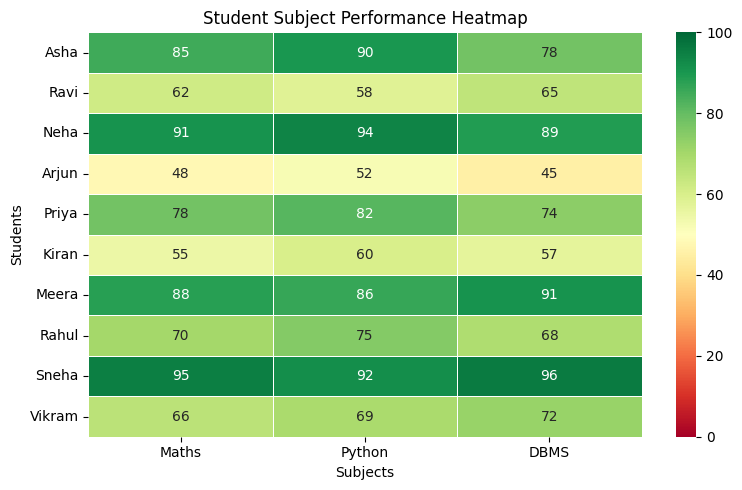

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

def create_subject_heatmap(data):
    subjects = ["Maths", "Python", "DBMS"]
    available = [col for col in subjects if col in data.columns]

    if not available or "Student" not in data.columns:
        return None

    marks = data.set_index("Student")[available]

    fig, ax = plt.subplots(figsize=(8, 5))

    sns.heatmap(
        marks,
        annot=True,
        fmt=".0f",
        cmap="RdYlGn",
        vmin=0,
        vmax=100,
        linewidths=0.5,
        ax=ax
    )

    ax.set_title("Student Subject Performance Heatmap")
    ax.set_xlabel("Subjects")
    ax.set_ylabel("Students")
    fig.tight_layout()

    return fig


create_subject_heatmap(df)
plt.show()


In [ ]:
print("Model loaded:", "model" in globals())
print("Tokenizer loaded:", "tokenizer" in globals())
print("Recommendations ready:", "generate_study_recommendations" in globals())
print("Heatmap ready:", "create_subject_heatmap" in globals())

Model loaded: True
Tokenizer loaded: True
Recommendations ready: True
Heatmap ready: True


In [9]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import gradio as gr

# ==================== DESIGN ====================
custom_css = """
.gradio-container {
    background: #0B1220 !important;
    color: #E2E8F0 !important;
    max-width: 1450px !important;
    margin: auto !important;
    font-family: Inter, sans-serif !important;
}
#app-header {
    background: linear-gradient(120deg, #123D45, #25285B) !important;
    border: 1px solid #31505F !important;
    border-radius: 22px !important;
    padding: 24px !important;
    margin-bottom: 18px !important;
}
#app-header h1 {
    color: #5EEAD4 !important;
    font-size: 34px !important;
}
#app-header p { color: #CBD5E1 !important; }
.block, .form, .panel {
    background: #111D2E !important;
    border: 1px solid #26384D !important;
    border-radius: 16px !important;
}
label, .prose h2, .prose h3 {
    color: #C4D2E5 !important;
}
input, textarea {
    background: #0C1727 !important;
    color: #F8FAFC !important;
    border: 1px solid #33465E !important;
    border-radius: 10px !important;
}
button.primary {
    background: linear-gradient(90deg, #0D9488, #6366F1) !important;
    color: white !important;
    border: none !important;
    border-radius: 12px !important;
    font-weight: bold !important;
}
button.primary:hover { filter: brightness(1.15); }
footer { display: none !important; }
"""

# ==================== KPI METRICS ====================
def calculate_kpis(data):
    subjects = [c for c in ["Maths", "Python", "DBMS"] if c in data.columns]
    total = len(data)

    averages = data[subjects].mean(axis=1) if subjects else None
    class_avg = round(float(averages.mean()), 2) if subjects and total else 0

    top = (
        str(data.loc[averages.idxmax(), "Student"])
        if subjects and "Student" in data.columns and total else "N/A"
    )

    low = int((data["Attendance"] < 75).sum()) if "Attendance" in data.columns else 0
    return total, class_avg, top, low


# ==================== QUESTION ANSWERS ====================
def answer_question(data, question):
    q = (question or "").lower()
    numeric = data.select_dtypes(include="number")
    subjects = [c for c in ["Maths", "Python", "DBMS"] if c in data.columns]

    if "column" in q or "header" in q:
        return "Columns: " + ", ".join(data.columns)

    if "attendance" in q and any(w in q for w in ["low", "below", "less"]):
        if "Attendance" not in data.columns:
            return "No Attendance column found."
        low_data = data[data["Attendance"] < 75]
        names = low_data["Student"].tolist() if "Student" in data.columns else []
        return f"Below 75% attendance: {len(low_data)} student(s). {names}"

    if any(w in q for w in ["how many", "number of students", "student count"]):
        return f"Total rows: {len(data)}"

    if any(w in q for w in ["top student", "highest marks", "scored highest"]):
        if subjects and "Student" in data.columns:
            avg = data[subjects].mean(axis=1)
            i = avg.idxmax()
            return f"Top student: {data.loc[i, 'Student']}, average {avg.loc[i]:.2f}"
        return numeric.max().to_string() if not numeric.empty else "No numeric data."

    if "average" in q or "mean" in q:
        if subjects:
            return f"Average marks by subject: {data[subjects].mean().round(2).to_dict()}"
        return numeric.mean().round(2).to_string() if not numeric.empty else "No numeric data."

    if "lowest" in q or "minimum" in q:
        return numeric.min().to_string() if not numeric.empty else "No numeric data."

    return "Try asking about average marks, top student, low attendance, lowest values, or column names."


# ==================== FLAN-T5 EXPLANATION ====================
def explain_result(question, result):
    try:
        prompt = (
            "Explain this data result in simple English in one or two sentences.\n"
            f"Question: {question}\nResult: {result}\nExplanation:"
        )
        inputs = tokenizer(
            prompt, return_tensors="pt",
            truncation=True, max_length=512
        )
        outputs = model.generate(**inputs, max_new_tokens=70, num_beams=4)
        return tokenizer.decode(outputs[0], skip_special_tokens=True)
    except Exception:
        return "The result above was calculated from the uploaded dataset."


# ==================== STUDY RECOMMENDATIONS ====================
def recommendations(data):
    subjects = [c for c in ["Maths", "Python", "DBMS"] if c in data.columns]
    if not subjects:
        return "Upload data containing Maths, Python, or DBMS marks."

    lines = []
    for subject in subjects:
        avg = data[subject].mean()
        if avg < 60:
            advice = "Focus on fundamentals and regular practice."
        elif avg < 75:
            advice = "Practise more questions to improve."
        else:
            advice = "Good progress—continue practising."

        lines.append(f"• {subject}: average {avg:.1f}/100. {advice}")

    if "Attendance" in data.columns:
        low = int((data["Attendance"] < 75).sum())
        lines.append(f"• Attendance: {low} student(s) are below 75%.")

    return "\n\n".join(lines)


# ==================== CHARTS ====================
def make_charts(data):
    subjects = [c for c in ["Maths", "Python", "DBMS"] if c in data.columns]

    # Performance doughnut
    pie_fig, ax = plt.subplots(figsize=(6, 4), facecolor="#111D2E")
    ax.set_facecolor("#111D2E")

    if subjects:
        avg = data[subjects].mean(axis=1)
        counts = [
            int((avg >= 85).sum()),
            int(((avg >= 70) & (avg < 85)).sum()),
            int((avg < 70).sum())
        ]
        labels = ["Excellent", "Good", "Needs Improvement"]
        pairs = [(l, c) for l, c in zip(labels, counts) if c > 0]

        if pairs:
            labels, counts = zip(*pairs)
            wedges, _, _ = ax.pie(
                counts, autopct="%1.1f%%", startangle=90,
                wedgeprops={"width": 0.43, "edgecolor": "#111D2E"},
                textprops={"color": "white"}
            )
            ax.legend(
                wedges, labels, loc="lower center",
                bbox_to_anchor=(0.5, -0.12), ncol=1,
                frameon=False, labelcolor="white"
            )
            ax.set_title("Performance Distribution", color="#5EEAD4", pad=15)
        else:
            ax.text(0.5, 0.5, "No performance data", color="white", ha="center")
    else:
        ax.text(0.5, 0.5, "Subject columns not found", color="white", ha="center")

    pie_fig.tight_layout()

    # Subject comparison
    bar_fig, bx = plt.subplots(figsize=(6, 4), facecolor="#111D2E")
    bx.set_facecolor("#111D2E")

    if subjects:
        means = data[subjects].mean()
        bars = bx.bar(
            means.index, means.values,
            color=["#5EEAD4", "#818CF8", "#FBBF24"][:len(subjects)]
        )
        bx.set_title("Average Marks by Subject", color="#5EEAD4")
        bx.set_ylabel("Average marks", color="#CBD5E1")
        bx.tick_params(colors="#CBD5E1")
        bx.set_ylim(0, 100)
        bx.bar_label(bars, fmt="%.1f", color="white", padding=3)
        for spine in bx.spines.values():
            spine.set_color("#33465E")
    else:
        bx.text(0.5, 0.5, "Subject columns not found", color="white", ha="center")

    bar_fig.tight_layout()

    # Subject heatmap
    heat_fig, hx = plt.subplots(
        figsize=(7, max(4, len(data) * 0.35)),
        facecolor="#111D2E"
    )
    hx.set_facecolor("#111D2E")

    if subjects and "Student" in data.columns:
        marks = data.set_index("Student")[subjects]
        sns.heatmap(
            marks, annot=True, fmt=".0f", cmap="RdYlGn",
            vmin=0, vmax=100, linewidths=0.5,
            linecolor="#111D2E", ax=hx,
            cbar_kws={"label": "Marks"}
        )
        hx.set_title("Student Subject Performance", color="#5EEAD4")
        hx.tick_params(colors="#CBD5E1")
        hx.set_xlabel("Subjects", color="#CBD5E1")
        hx.set_ylabel("Students", color="#CBD5E1")
    else:
        hx.text(0.5, 0.5, "Student and subject columns required",
                color="white", ha="center")

    heat_fig.tight_layout()
    return pie_fig, bar_fig, heat_fig


# ==================== ANALYSIS ====================
def analyze_dashboard(file, question):
    if file is None:
        raise gr.Error("Please upload a CSV file.")

    try:
        path = file.name if hasattr(file, "name") else file
        data = pd.read_csv(path)
        if data.empty:
            raise gr.Error("The CSV file is empty.")

        total, class_avg, top, low = calculate_kpis(data)
        numeric = data.select_dtypes(include="number")
        summary = (
            numeric.describe().round(2).to_string()
            if not numeric.empty else "No numeric columns found."
        )

        pie_fig, bar_fig, heat_fig = make_charts(data)
        result = answer_question(data, question)

        if result.startswith("Try asking"):
            final_answer = result
        else:
            final_answer = (
                f"CALCULATED RESULT\n{result}\n\n"
                f"AI EXPLANATION\n{explain_result(question, result)}"
            )

        return (
            str(total), str(class_avg), top, str(low),
            data.head(10), summary, pie_fig, bar_fig,
            heat_fig, final_answer, recommendations(data)
        )

    except gr.Error:
        raise
    except Exception as e:
        raise gr.Error(f"Could not analyze CSV: {e}")


# ==================== DASHBOARD UI ====================
with gr.Blocks(theme=gr.themes.Base(), css=custom_css) as demo:
    gr.HTML("""
    <div id="app-header">
      <h1>✦ EduPulse AI</h1>
      <p>STUDENT PERFORMANCE INTELLIGENCE · Analyze. Understand. Improve.</p>
    </div>
    """)

    gr.Markdown("## ◈ Academic Overview")
    csv_file = gr.File(label="📂 Upload your student CSV", file_types=[".csv"])

    with gr.Row():
        total_box = gr.Textbox(label="👥 TOTAL STUDENTS", interactive=False)
        average_box = gr.Textbox(label="📊 CLASS AVERAGE", interactive=False)
        top_box = gr.Textbox(label="🏆 TOP PERFORMER", interactive=False)
        low_box = gr.Textbox(label="⚠️ LOW ATTENDANCE", interactive=False)

    gr.Markdown("## ◈ Explore Performance")
    question = gr.Textbox(
        label="Ask your data analyst",
        placeholder="e.g. Who is the top student?"
    )
    run_button = gr.Button("✦ Analyze Dataset", variant="primary")

    with gr.Row():
        preview = gr.Dataframe(label="📋 Dataset Preview")
        summary = gr.Textbox(label="📈 Statistical Summary", lines=8)

    with gr.Row():
        pie_output = gr.Plot(label="◉ Performance Distribution")
        bar_output = gr.Plot(label="▥ Subject Comparison")

    heat_output = gr.Plot(label="▦ Subject Weakness Heatmap")
    answer_output = gr.Textbox(label="✦ AI Analysis & Explanation", lines=6)
    recommendations_output = gr.Textbox(label="💡 Study Recommendations", lines=8)

    run_button.click(
        fn=analyze_dashboard,
        inputs=[csv_file, question],
        outputs=[
            total_box, average_box, top_box, low_box,
            preview, summary, pie_output, bar_output,
            heat_output, answer_output, recommendations_output
        ]
    )

    gr.Examples(
        examples=[
            ["What is the average mark?"],
            ["Who is the top student?"],
            ["Which students have low attendance?"],
            ["What are the column names?"]
        ],
        inputs=question
    )

demo.launch(share=True)


/tmp/ipykernel_2649/2712395441.py:277: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Base(), css=custom_css) as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://afeb7443e92b7e694c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
